# Final results charts (Week 8)

**Owner:** Salah · Charts for the final report and presentation, built from the committed results of earlier weeks so they can be regenerated in one run.

| Figure | Shows | Source |
|---|---|---|
| 1 | S&P 500 and the 13 labeled stress episodes | `sp500_close.parquet`, `docs/stress_periods.csv` (Week 1) |
| 2 | Volatility forecasts vs what happened, and error in calm vs stress | Grace's walk-forward predictions (Week 6) |
| 3 | Same-day detection vs 20-day early warning | `outputs/salah_week5/` (Week 5) |
| 4 | How early each signal warned before each episode | `outputs/rishi_week6/lead_times_by_episode_start.csv` (Week 6) |
| 5 | Episodes warned vs false alarms, under the two warning definitions | `outputs/rishi_week6/`, `outputs/salah_week6/` (Week 6) |

Saved to `notebooks/outputs/final_charts/` as PNG (200 dpi). Style: one light theme for print, a fixed color per entity (VIX blue, network orange, model aqua), thin lines, recessive grid.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "notebooks" / "outputs"
SNAP = ROOT / "dashboard" / "snapshot"
FIG = OUT / "final_charts"
FIG.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # validated categorical slots 1-3
STRESS = "#e34948"                                        # episode shading (low alpha)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    plt.show()

def first(*paths):
    for p in paths:
        if Path(p).exists():
            return Path(p)
    raise FileNotFoundError(paths[0])

episodes = pd.read_csv(ROOT / "docs" / "stress_periods.csv", parse_dates=["start", "end"])
def shade(ax, lo=None, hi=None):
    for e in episodes.itertuples():
        if (lo is None or e.end >= lo) and (hi is None or e.start <= hi):
            ax.axvspan(e.start, e.end, color=STRESS, alpha=0.13, lw=0, zorder=0)

## Figure 1. The 13 stress episodes

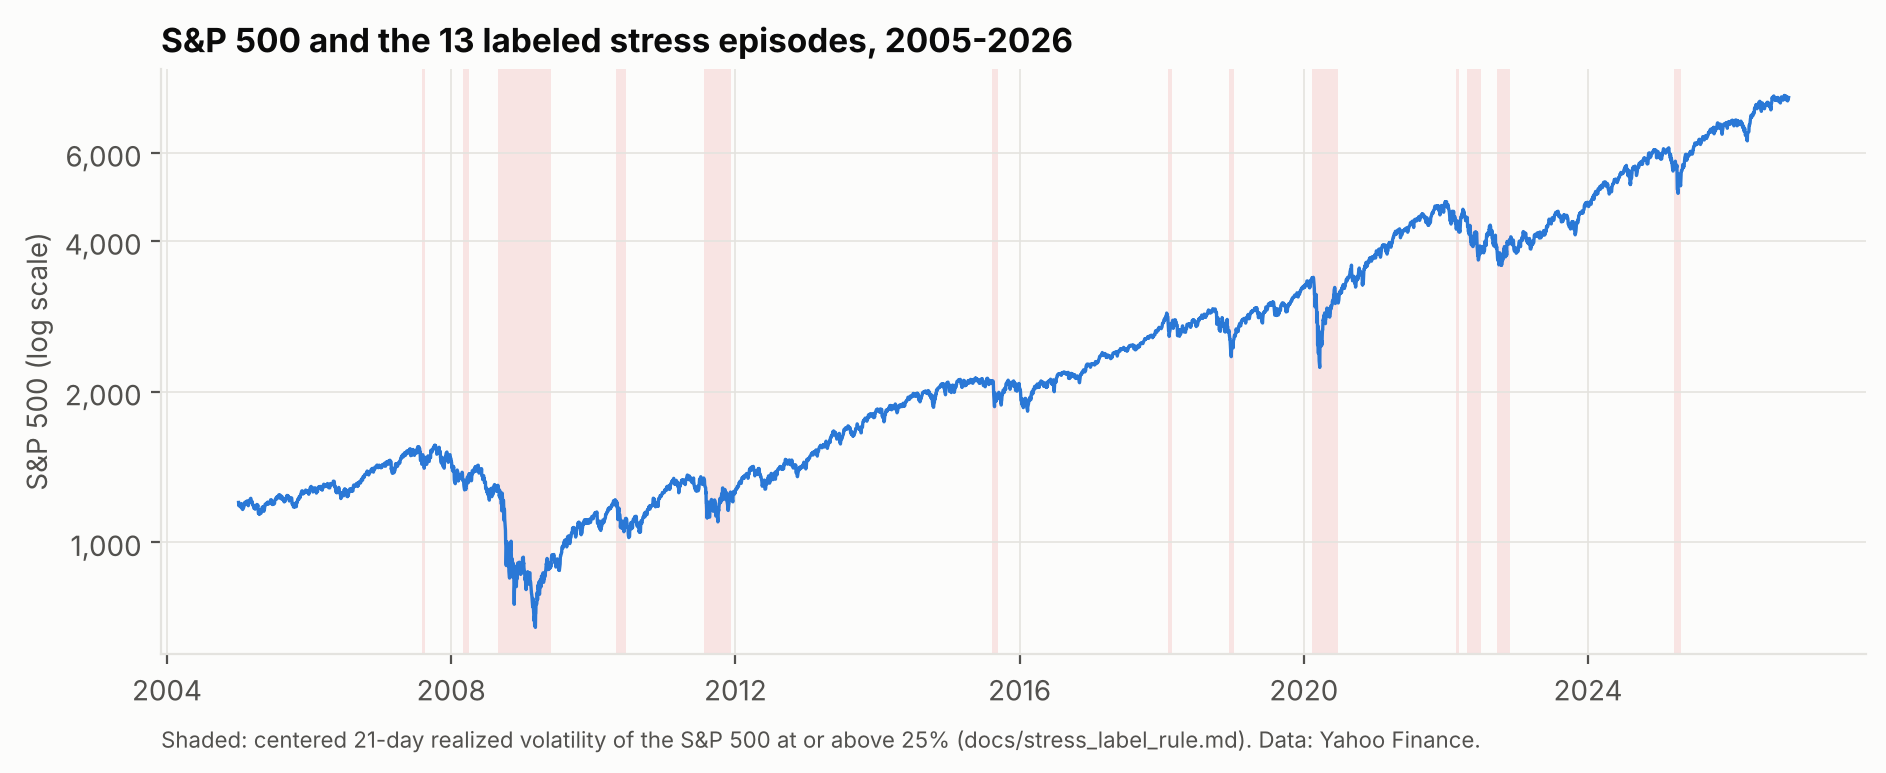

In [2]:
gspc = pd.read_parquet(ROOT / "data" / "processed" / "sp500_close.parquet")["^GSPC"].dropna()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(gspc.index, gspc, color=BLUE, lw=1.2)
ax.set_yscale("log")
ax.set_yticks([1000, 2000, 4000, 6000]); ax.set_yticklabels(["1,000", "2,000", "4,000", "6,000"])
ax.minorticks_off()
shade(ax)
ax.set_title(f"S&P 500 and the {len(episodes)} labeled stress episodes, 2005-2026")
ax.set_ylabel("S&P 500 (log scale)")
ax.text(0, -0.16, "Shaded: centered 21-day realized volatility of the S&P 500 at or above 25% (docs/stress_label_rule.md). "
        "Data: Yahoo Finance.", transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, "fig1_stress_episodes.png")

## Figure 2. Volatility forecasts react to stress, they don't anticipate it

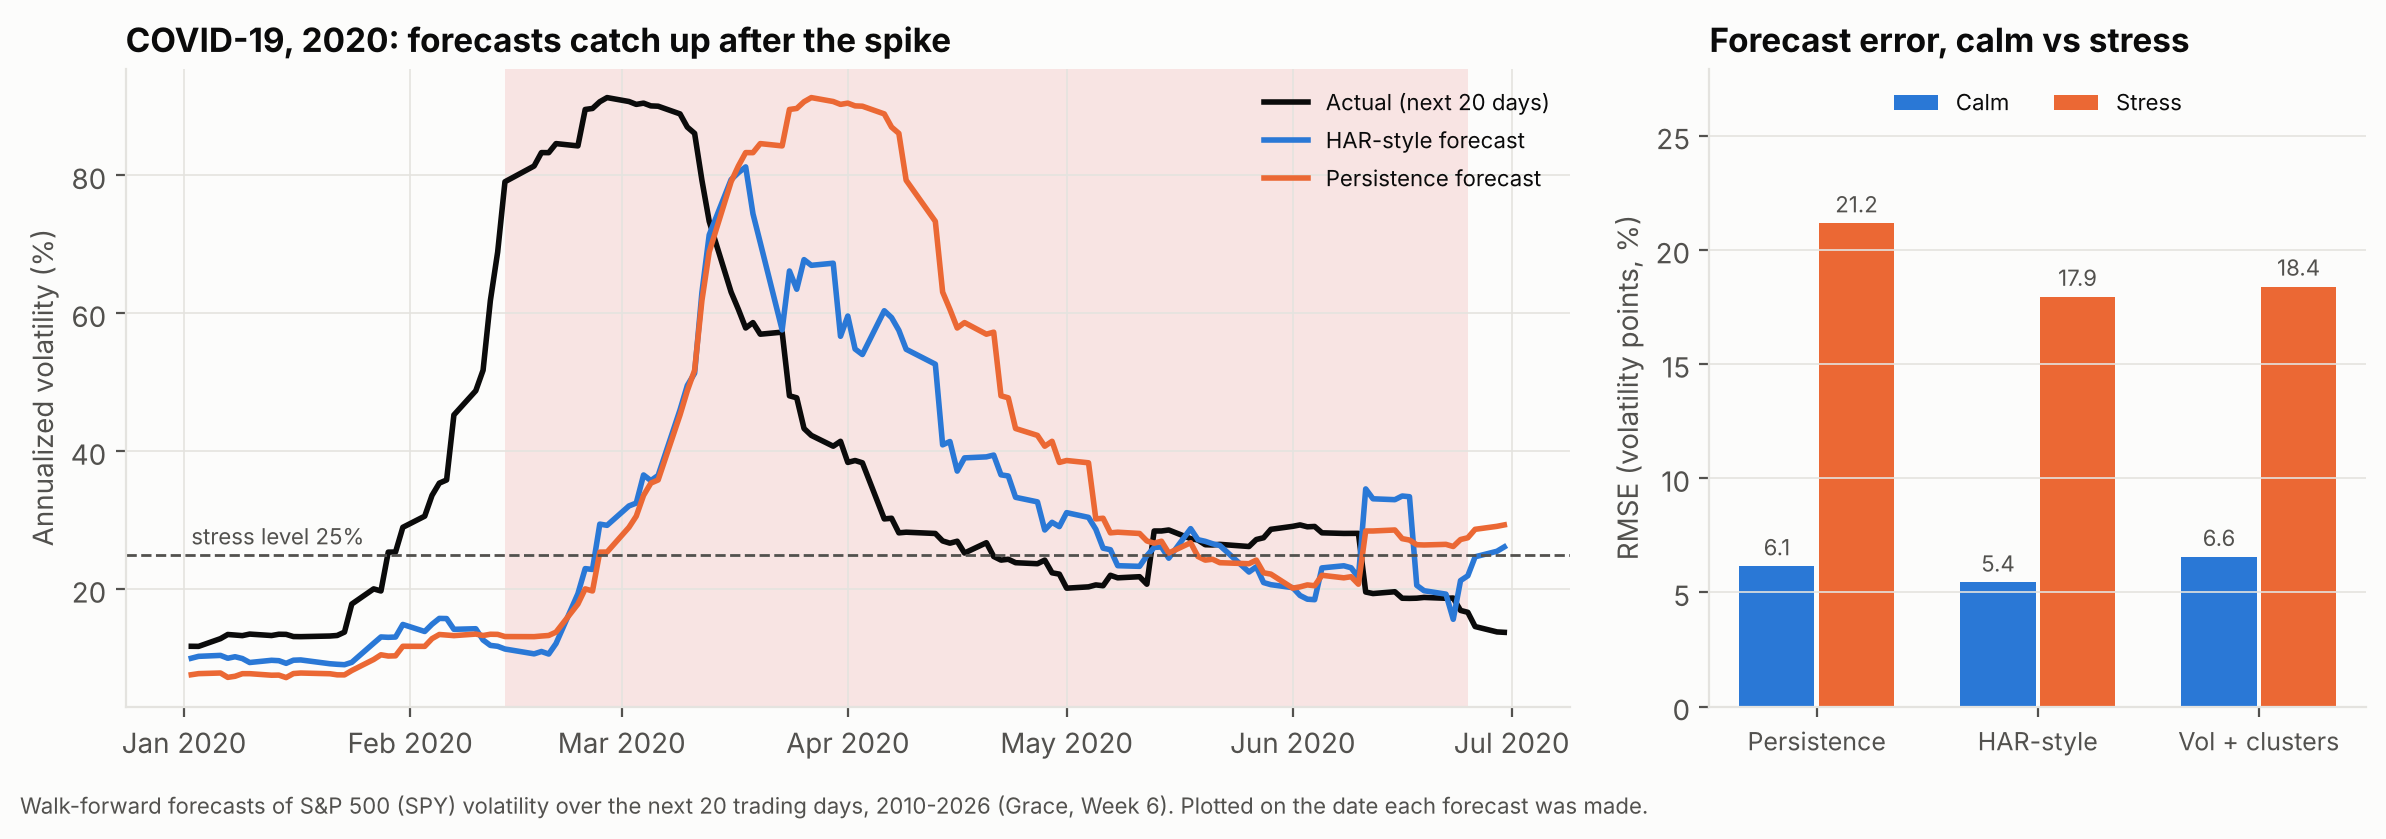

In [3]:
pred = pd.read_csv(first(OUT / "grace_week6" / "walk_forward_predictions.csv", SNAP / "walk_forward_predictions.csv"),
                   parse_dates=["date"]).set_index("date")
by_stress = pd.read_csv(first(OUT / "grace_week6" / "stress_period_performance.csv", SNAP / "stress_period_performance.csv"))

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2.2, 1]})
d = pred.loc["2020-01-02":"2020-06-30"]
a.plot(d.index, d["target"] * 100, color=INK, lw=2, label="Actual (next 20 days)")
a.plot(d.index, d["HAR-style"] * 100, color=BLUE, label="HAR-style forecast")
a.plot(d.index, d["Persistence"] * 100, color=ORANGE, label="Persistence forecast")
a.axhline(25, color=INK2, ls="--", lw=1)
a.text(d.index[0], 26.5, "stress level 25%", ha="left", fontsize=8, color=INK2)
shade(a, d.index[0], d.index[-1])
a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
a.set_ylabel("Annualized volatility (%)")
a.set_title("COVID-19, 2020: forecasts catch up after the spike")
a.legend(loc="upper right", fontsize=8)

models = ["Persistence", "HAR-style", "Volatility + clusters"]
t = by_stress.assign(period=by_stress["stress"].map({0.0: "Calm", 1.0: "Stress"})).pivot(index="model", columns="period", values="RMSE").reindex(models)
x = np.arange(len(models)); w = 0.36
for i, (per, col) in enumerate([("Calm", BLUE), ("Stress", ORANGE)]):
    bars = b.bar(x + (i - 0.5) * w, t[per] * 100, width=w - 0.02, color=col, label=per)
    b.bar_label(bars, fmt="%.1f", fontsize=8, color=INK2, padding=2)
b.set_xticks(x); b.set_xticklabels(["Persistence", "HAR-style", "Vol + clusters"], fontsize=9)
b.set_ylabel("RMSE (volatility points, %)")
b.set_title("Forecast error, calm vs stress")
b.legend(fontsize=8, loc="upper center", ncol=2); b.set_ylim(0, t.max().max() * 100 * 1.32); b.grid(axis="x", visible=False)
fig.text(0.01, -0.03, "Walk-forward forecasts of S&P 500 (SPY) volatility over the next 20 trading days, 2010-2026 (Grace, Week 6). "
         "Plotted on the date each forecast was made.", fontsize=8, color=INK2)
plt.tight_layout(); save(fig, "fig2_forecasts.png")

## Figure 3. Detecting stress today is easy; warning 20 days ahead is not

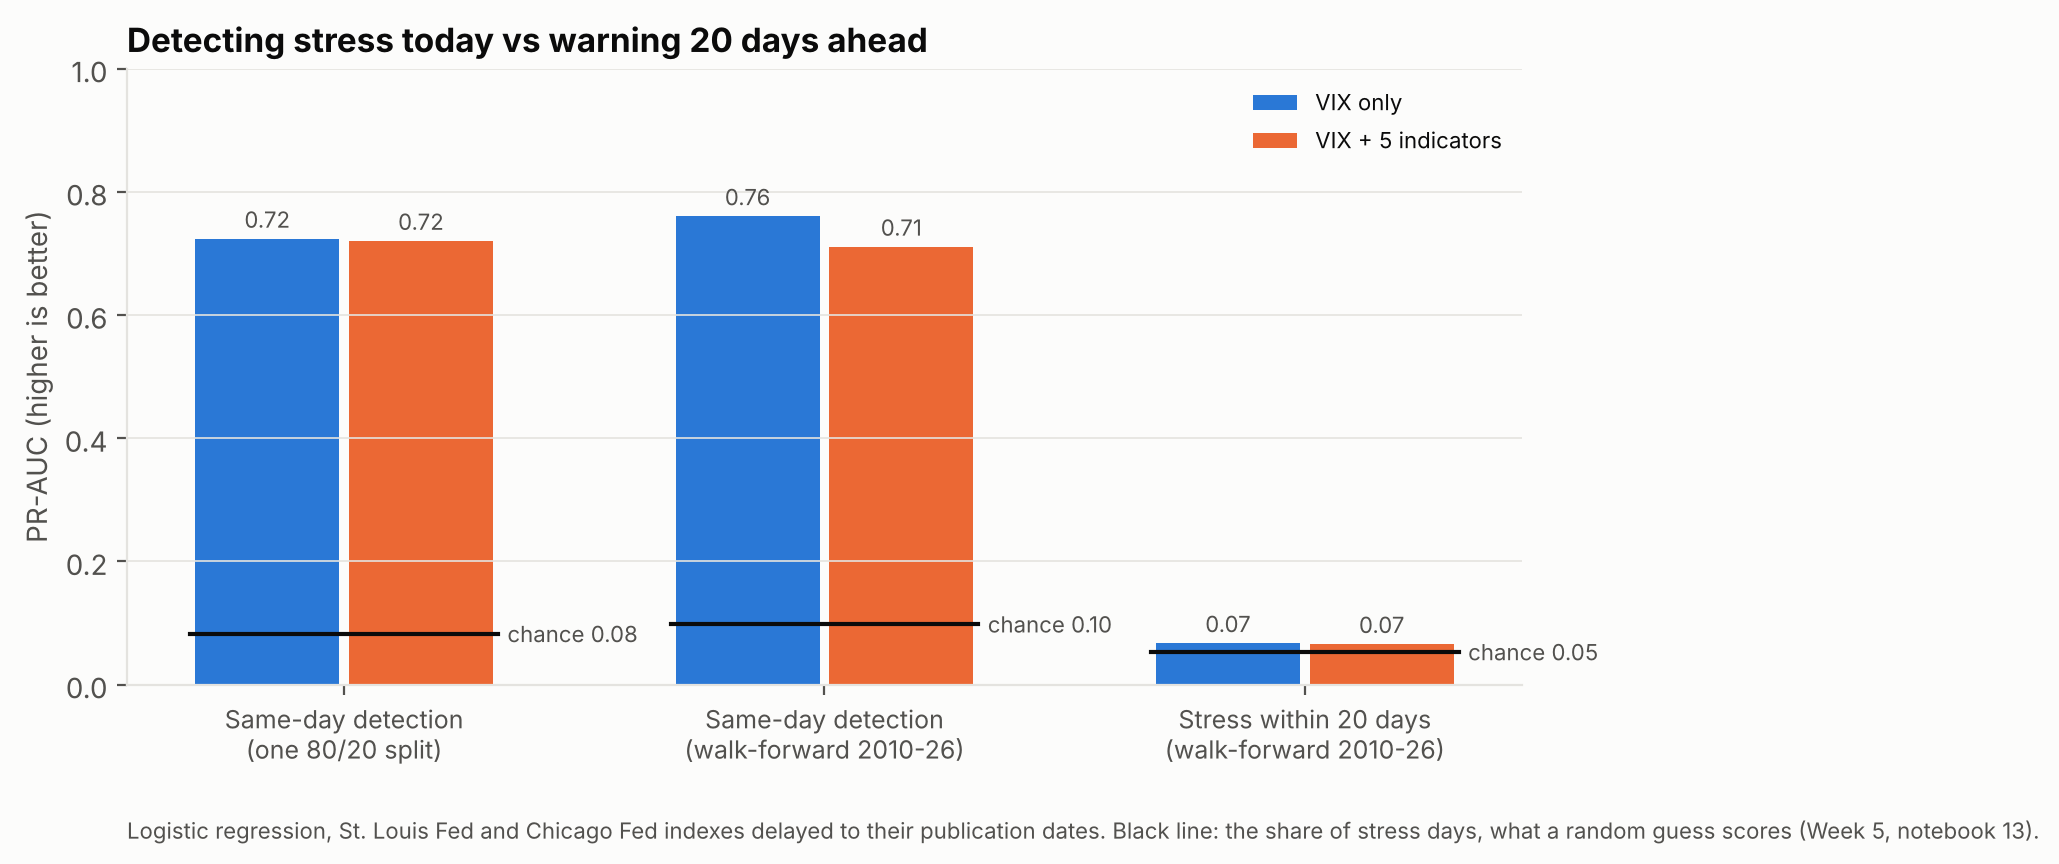

In [4]:
wf = pd.read_csv(OUT / "salah_week5" / "walk_forward_comparison.csv", index_col=[0, 1])
wf.index = wf.index.set_levels([s.strip() for s in wf.index.levels[0]], level=0)
setups = [("A2 FRED lagged", "Same-day detection\n(one 80/20 split)"),
          ("B  walk-forward".strip(), "Same-day detection\n(walk-forward 2010-26)"),
          ("C  early warning, walk-forward".replace("  ", " "), "Stress within 20 days\n(walk-forward 2010-26)")]
keys = list(wf.index.levels[0])
def find(prefix):
    return next(k for k in keys if k.replace(" ", "").startswith(prefix.split()[0].replace(" ", "")))
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(setups)); w = 0.32
for i, (model, col) in enumerate([("VIX only", BLUE), ("Combined", ORANGE)]):
    vals = [wf.loc[(find(s), model), "PR-AUC"] for s, _ in setups]
    bars = ax.bar(x + (i - 0.5) * w, vals, width=w - 0.02, color=col, label=model if model != "Combined" else "VIX + 5 indicators")
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color=INK2, padding=2)
base = [wf.loc[(find(s), "VIX only"), "base rate"] for s, _ in setups]
for xi, br in zip(x, base):
    ax.plot([xi - w, xi + w], [br, br], color=INK, lw=1.5)
    ax.text(xi + w + 0.02, br, f"chance {br:.2f}", va="center", fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xticklabels([lab for _, lab in setups], fontsize=9)
ax.set_ylim(0, 1); ax.set_ylabel("PR-AUC (higher is better)")
ax.set_title("Detecting stress today vs warning 20 days ahead")
ax.legend(fontsize=8, loc="upper right"); ax.grid(axis="x", visible=False)
ax.text(0, -0.25, "Logistic regression, St. Louis Fed and Chicago Fed indexes delayed to their publication dates. "
        "Black line: the share of stress days, what a random guess scores (Week 5, notebook 13).",
        transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, "fig3_detection_vs_warning.png")

## Figure 4. How early each signal warned, episode by episode

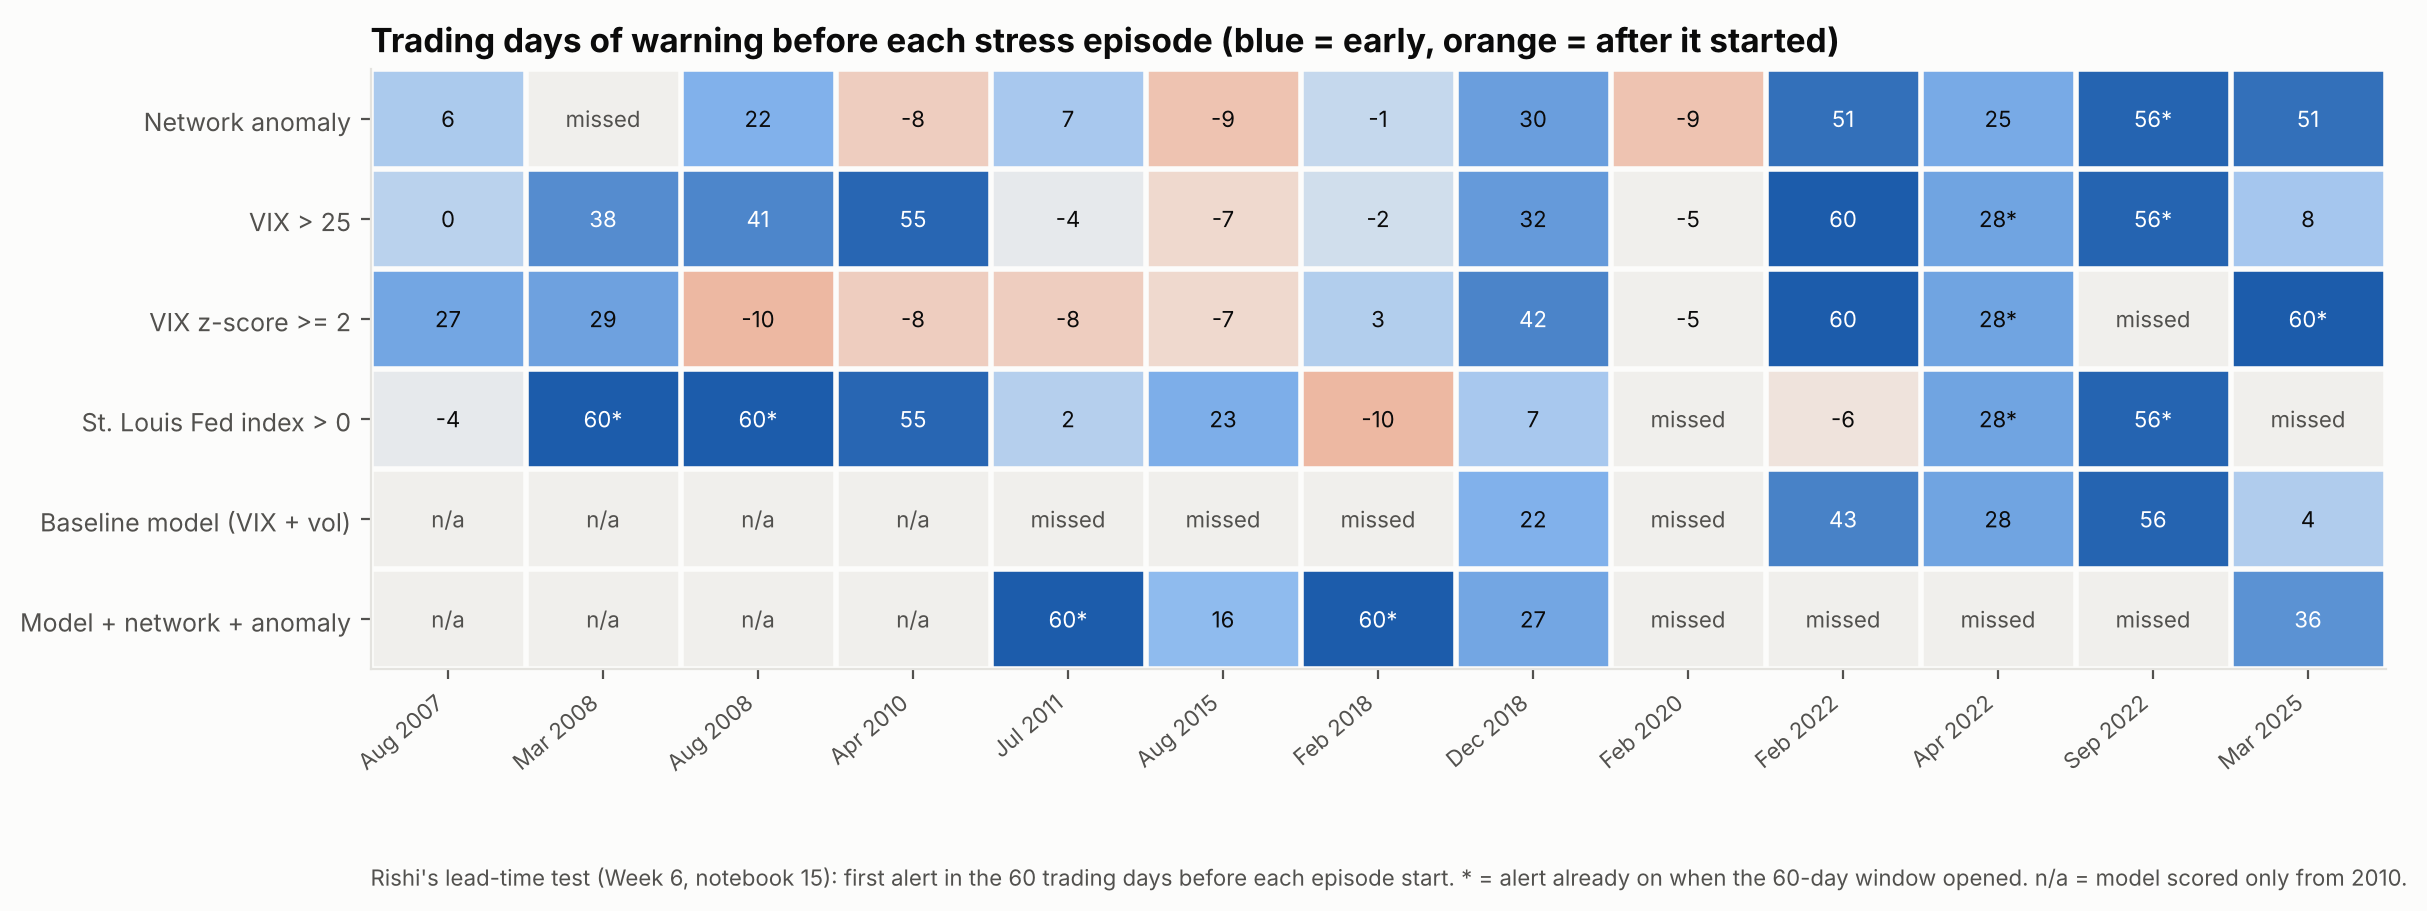

In [5]:
lead = pd.read_csv(OUT / "rishi_week6" / "lead_times_by_episode_start.csv")
signals = ["Network anomaly (combined)", "VIX > 25", "VIX z >= 2", "STLFSI4 > 0 (lagged)",
           "Baseline model alert (VIX + vol)", "Model alert (+ z + IF)"]
labels = ["Network anomaly", "VIX > 25", "VIX z-score >= 2", "St. Louis Fed index > 0",
          "Baseline model (VIX + vol)", "Model + network + anomaly"]
short = [f"{s:%b %Y}" for s in pd.to_datetime(lead["start"])]
vals = np.full((len(signals), len(lead)), np.nan); text = [[""] * len(lead) for _ in signals]
for i, s in enumerate(signals):
    for j, v in enumerate(lead[s].astype(object)):
        if pd.isna(v):
            text[i][j] = "n/a"
        elif str(v) == "missed":
            text[i][j] = "missed"
        else:
            num = float(str(v).rstrip("*"))
            vals[i, j] = num
            text[i][j] = f"{int(num)}" + ("*" if str(v).endswith("*") else "")
cmap = LinearSegmentedColormap.from_list("lead", ["#ec835a", "#f0efec", "#86b6ef", "#1c5cab"])
norm = TwoSlopeNorm(vmin=-15, vcenter=0, vmax=60)
fig, ax = plt.subplots(figsize=(13, 3.9))
ax.imshow(np.ma.masked_invalid(vals), cmap=cmap, norm=norm, aspect="auto")
ax.set_facecolor("#f0efec")
for i in range(len(signals)):
    for j in range(len(lead)):
        v = vals[i, j]
        dark = not np.isnan(v) and v >= 35
        ax.text(j, i, text[i][j], ha="center", va="center", fontsize=8,
                color="white" if dark else (INK2 if np.isnan(v) else INK))
ax.set_xticks(range(len(lead))); ax.set_xticklabels(short, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(signals))); ax.set_yticklabels(labels, fontsize=9)
ax.set_xticks(np.arange(-.5, len(lead)), minor=True); ax.set_yticks(np.arange(-.5, len(signals)), minor=True)
ax.grid(which="minor", color=SURFACE, lw=2); ax.grid(which="major", visible=False); ax.tick_params(which="minor", length=0)
ax.set_title("Trading days of warning before each stress episode (blue = early, orange = after it started)")
ax.text(0, -0.36, "Rishi's lead-time test (Week 6, notebook 15): first alert in the 60 trading days before each episode start. "
        "* = alert already on when the 60-day window opened. n/a = model scored only from 2010.",
        transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, "fig4_lead_by_episode.png")

## Figure 5. Episodes warned vs false alarms, under two definitions of "a warning"

The team ran two Week 6 tests that count warnings differently:

* **Lead-time test (Rishi):** an episode counts as warned if the signal was on at any point in the 60 trading days before it started, 2005-2026, 13 episodes.
* **False-alarm test (Salah):** a warning counts only if the episode starts within 20 trading days after the alert goes off; an alert that stays on for months is a false alarm. 2010-2026, 9 episodes.

The same signals look much better under the first definition. The report should state which one it uses for its main claim.

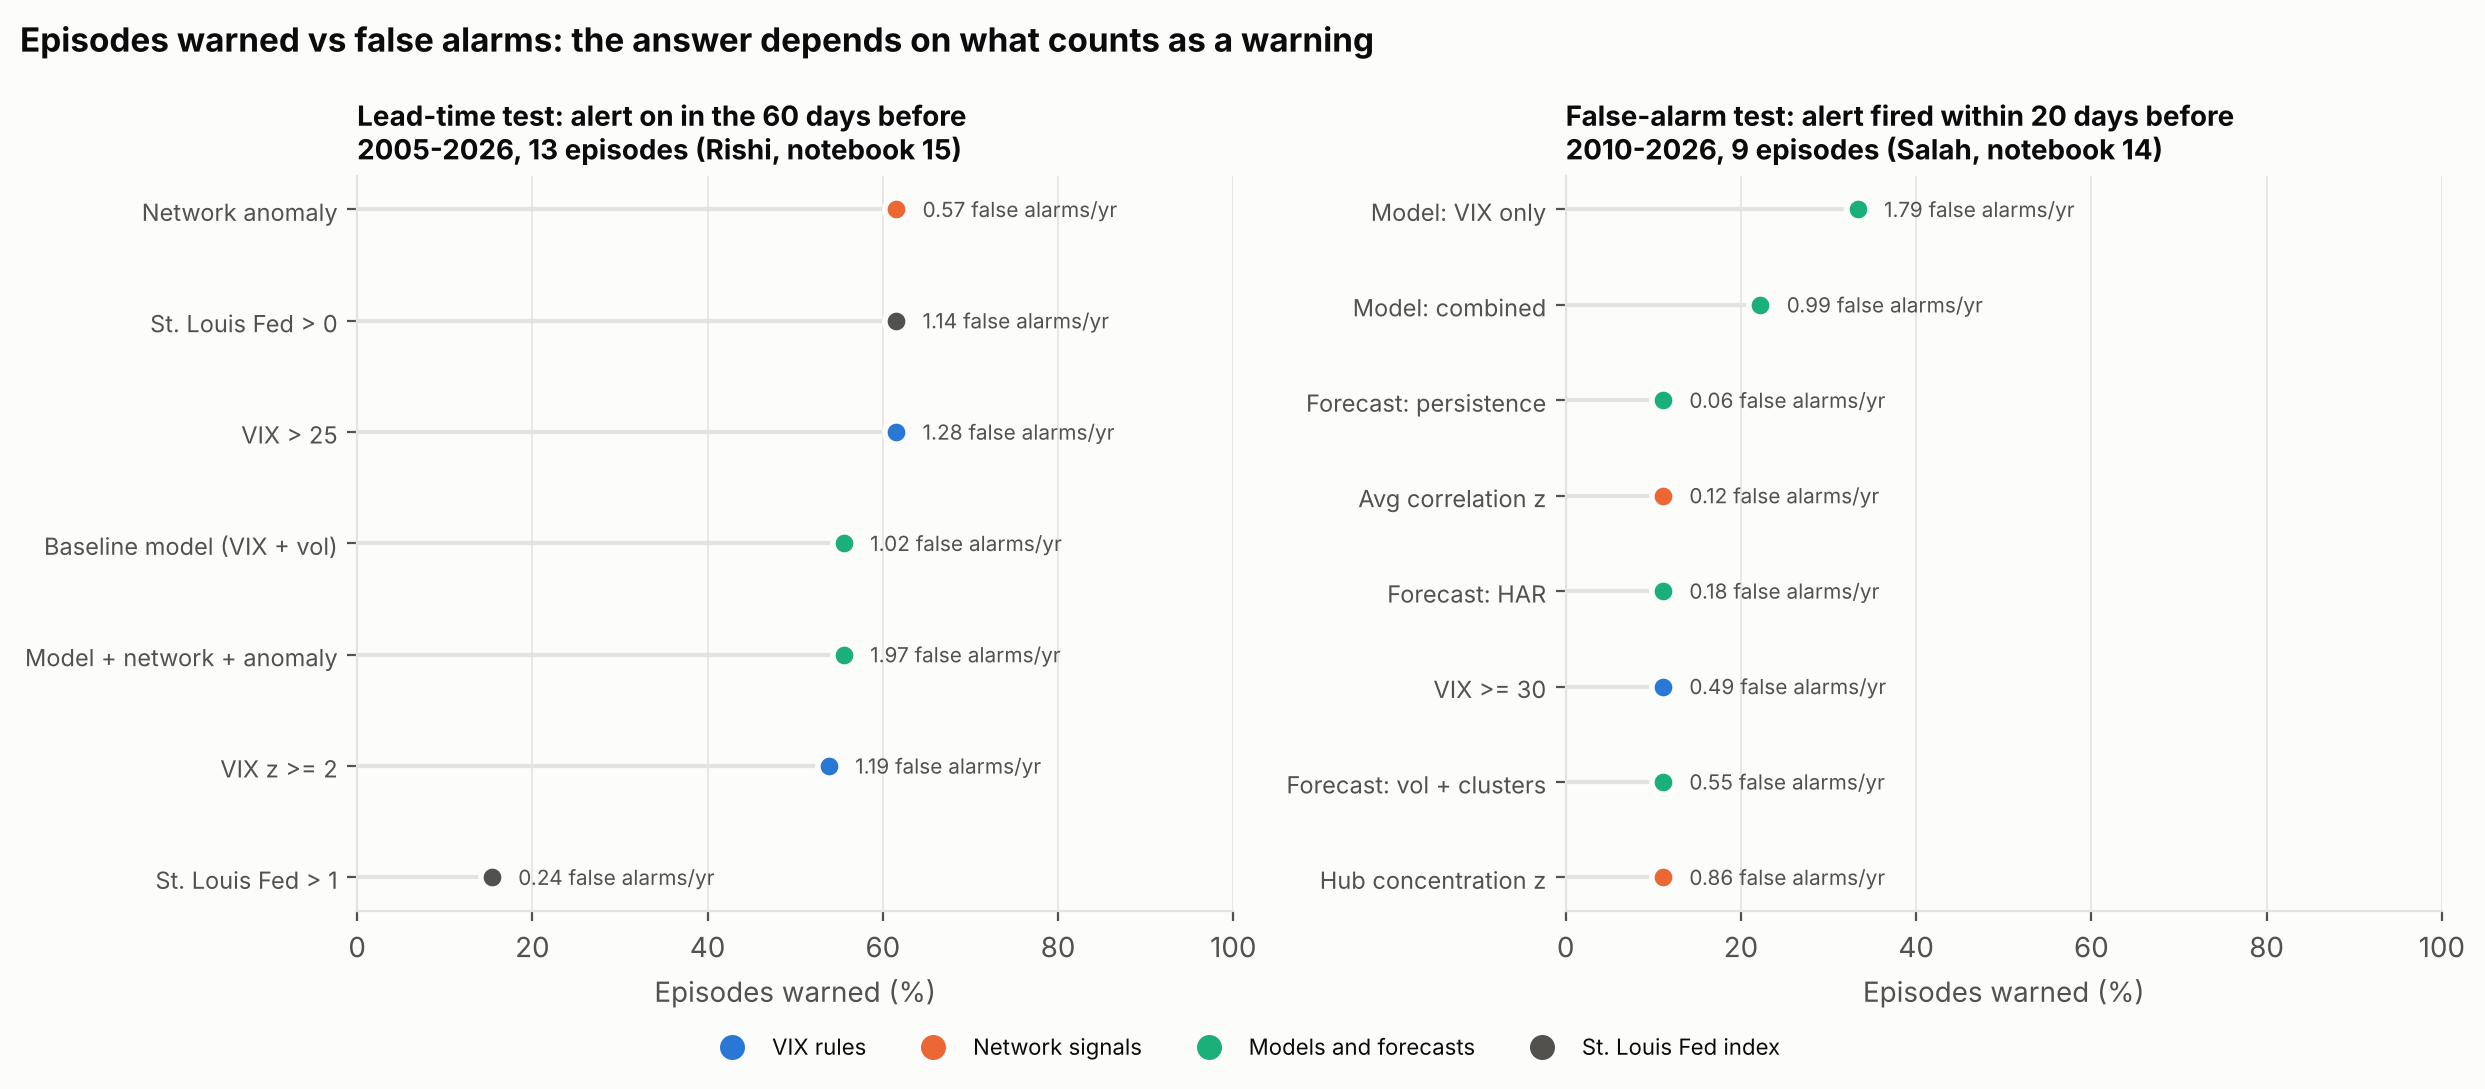

In [6]:
rs = pd.read_csv(OUT / "rishi_week6" / "signal_summary.csv")
rs = rs[(rs["start_col"] == "start") & (rs["signal"] != "Network z-score only")].copy()
rs["share"] = rs["warned_early"] / rs["episodes_scored"]
ss = pd.read_csv(OUT / "salah_week6" / "false_alarms_overall.csv", index_col=0)
ss["share"] = ss["episodes_caught"] / ss["episodes"]

def kind(name):
    n = name.lower()
    return BLUE if "vix" in n and "model" not in n else ORANGE if "network" in n else AQUA if ("model" in n or "forecast" in n) else INK2

SHORT = {"Network anomaly (combined)": "Network anomaly", "VIX > 25": "VIX > 25", "VIX z >= 2": "VIX z >= 2",
         "STLFSI4 > 0 (lagged)": "St. Louis Fed > 0", "STLFSI4 > 1 (lagged)": "St. Louis Fed > 1",
         "Model alert (+ z + IF)": "Model + network + anomaly", "Baseline model alert (VIX + vol)": "Baseline model (VIX + vol)",
         "VIX >= 30": "VIX >= 30", "Forecast: Persistence": "Forecast: persistence", "Forecast: HAR-style": "Forecast: HAR",
         "Forecast: Volatility + clusters": "Forecast: vol + clusters", "Model: VIX only": "Model: VIX only",
         "Model: Combined": "Model: combined", "Network: avg_corr z >= 1.5": "Avg correlation z",
         "Network: strength_top10 z >= 1.5": "Hub concentration z"}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, df, title in [(axes[0], rs.set_index("signal"), "Lead-time test: alert on in the 60 days before\n2005-2026, 13 episodes (Rishi, notebook 15)"),
                      (axes[1], ss, "False-alarm test: alert fired within 20 days before\n2010-2026, 9 episodes (Salah, notebook 14)")]:
    d = df.sort_values(["share", "false_alarms_per_year"], ascending=[True, False])
    y = np.arange(len(d))
    for yi, (n, r) in zip(y, d.iterrows()):
        ax.plot([0, r["share"] * 100], [yi, yi], color=GRID, lw=1.5, zorder=1)
        ax.scatter(r["share"] * 100, yi, s=70, color=kind(n), edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.text(r["share"] * 100 + 3, yi, f"{r['false_alarms_per_year']:.2f} false alarms/yr", va="center",
                fontsize=7.5, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels([SHORT.get(n, n) for n in d.index], fontsize=8.5)
    ax.set_xlim(0, 100); ax.set_xlabel("Episodes warned (%)")
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=8, label=l) for c, l in
           [(BLUE, "VIX rules"), (ORANGE, "Network signals"), (AQUA, "Models and forecasts"), (INK2, "St. Louis Fed index")]]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Episodes warned vs false alarms: the answer depends on what counts as a warning", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout(); save(fig, "fig5_warned_vs_false_alarms.png")

In [7]:
print("Saved:", *sorted(p.name for p in FIG.glob("*.png")), sep="\n  ")

Saved:
  fig1_stress_episodes.png
  fig2_forecasts.png
  fig3_detection_vs_warning.png
  fig4_lead_by_episode.png
  fig5_warned_vs_false_alarms.png
